In [1]:
from pathlib import Path

PROJECT = Path("/kaggle/working/ubiris_v2_project")

print("Project exists:", PROJECT.exists())

if PROJECT.exists():
    for folder in sorted(PROJECT.iterdir()):
        if folder.is_dir():
            files = [p for p in folder.rglob("*") if p.is_file()]
            print(f"{folder.name}: {len(files)} files")
else:
    print("Project directory not found in this session.")

Project exists: False
Project directory not found in this session.


In [2]:

from pathlib import Path

for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
    print(f"\n{'=' * 15} {root} {'=' * 15}")
    if root.exists():
        for p in list(root.iterdir())[:30]:
            print(("DIR  " if p.is_dir() else "FILE "), p.name)
    else:
        print("Not found")



=============== /kaggle/input ===============
DIR   datasets

=============== /kaggle/working ===============
DIR   .virtual_documents


In [4]:

from pathlib import Path

INPUT = Path("/kaggle/input")
PROJECT = Path("/kaggle/working/ubiris_v2_project")

print("Searching extracted result files...\n")

for p in sorted(INPUT.iterdir()):
    print(f"\nDataset: {p.name}")
    if p.is_dir():
        for sub in sorted(p.iterdir()):
            if sub.is_dir():
                files = [f for f in sub.rglob("*") if f.is_file()]
                print(f"  {sub.name}: {len(files)} files")

print("\nWorking project exists:", PROJECT.exists())


Searching extracted result files...


Dataset: datasets
  pranavsunilwagh: 20134 files

Working project exists: False


In [5]:

from pathlib import Path

ROOT = Path("/kaggle/input/datasets/pranavsunilwagh")

print("Searching for the 10 notebook result folders...\n")

for p in sorted(ROOT.rglob("*")):
    if p.is_dir() and "Notebook" in p.name and "Results" in p.name:
        files = [f for f in p.rglob("*") if f.is_file()]
        print(f"{p}  |  {len(files)} files")


Searching for the 10 notebook result folders...

/kaggle/input/datasets/pranavsunilwagh/ubiris-v2-notebook-results/UBIRIS_V2_Notebook01_Results  |  4 files
/kaggle/input/datasets/pranavsunilwagh/ubiris-v2-notebook-results/UBIRIS_V2_Notebook02_Results  |  5802 files
/kaggle/input/datasets/pranavsunilwagh/ubiris-v2-notebook-results/UBIRIS_V2_Notebook03_Results  |  5 files
/kaggle/input/datasets/pranavsunilwagh/ubiris-v2-notebook-results/UBIRIS_V2_Notebook04_Results  |  7 files
/kaggle/input/datasets/pranavsunilwagh/ubiris-v2-notebook-results/UBIRIS_V2_Notebook05_Results  |  8490 files
/kaggle/input/datasets/pranavsunilwagh/ubiris-v2-notebook-results/UBIRIS_V2_Notebook06_Results  |  3 files
/kaggle/input/datasets/pranavsunilwagh/ubiris-v2-notebook-results/UBIRIS_V2_Notebook07_Results  |  10 files
/kaggle/input/datasets/pranavsunilwagh/ubiris-v2-notebook-results/UBIRIS_V2_Notebook08_Results  |  5 files
/kaggle/input/datasets/pranavsunilwagh/ubiris-v2-notebook-results/UBIRIS_V2_Notebook09_R

In [6]:

from pathlib import Path
import shutil

INPUT_ROOT = Path(
    "/kaggle/input/datasets/pranavsunilwagh/"
    "ubiris-v2-notebook-results"
)
PROJECT = Path("/kaggle/working/ubiris_v2_project")

PROJECT.mkdir(parents=True, exist_ok=True)

print("RESTORING NOTEBOOK RESULTS")
print("=" * 60)

total_copied = 0

for i in range(1, 11):
    folder_name = f"UBIRIS_V2_Notebook{i:02d}_Results"
    source = INPUT_ROOT / folder_name

    if not source.is_dir():
        print(f"NOT FOUND: {folder_name}")
        continue

    copied = 0

    for src_file in source.rglob("*"):
        if not src_file.is_file():
            continue

        # Preserve the paths stored inside each results archive.
        relative_path = src_file.relative_to(source)
        destination = PROJECT / relative_path
        destination.parent.mkdir(parents=True, exist_ok=True)

        shutil.copy2(src_file, destination)
        copied += 1

    total_copied += copied
    print(f"Notebook {i:02d}: copied {copied} files")

print("\n" + "=" * 60)
print("TOTAL FILES COPIED:", total_copied)
print("PROJECT DIRECTORY:", PROJECT)
print("PROJECT EXISTS:", PROJECT.exists())

print("\nRESTORED TOP-LEVEL CONTENTS:")
for item in sorted(PROJECT.iterdir()):
    if item.is_dir():
        count = sum(1 for p in item.rglob("*") if p.is_file())
        print(f"DIR  {item.name}: {count} files")
    else:
        print(f"FILE {item.name}")


RESTORING NOTEBOOK RESULTS
Notebook 01: copied 4 files
Notebook 02: copied 5802 files
Notebook 03: copied 5 files
Notebook 04: copied 7 files
Notebook 05: copied 8490 files
Notebook 06: copied 3 files
Notebook 07: copied 10 files
Notebook 08: copied 5 files
Notebook 09: copied 4 files
Notebook 10: copied 4 files

TOTAL FILES COPIED: 14334
PROJECT DIRECTORY: /kaggle/working/ubiris_v2_project
PROJECT EXISTS: True

RESTORED TOP-LEVEL CONTENTS:
FILE UBIRIS_V2_baseline_resnet18_best.pth
FILE UBIRIS_V2_baseline_test_metrics.csv
FILE UBIRIS_V2_baseline_test_metrics.json
FILE UBIRIS_V2_baseline_training_history.csv
FILE UBIRIS_V2_dataset_summary.json
FILE UBIRIS_V2_image_metadata.csv
FILE UBIRIS_V2_image_quality_metrics.csv
FILE UBIRIS_V2_quality_assessment_summary.json
FILE UBIRIS_V2_quality_errors.csv
FILE UBIRIS_V2_quality_metrics_distribution.png
FILE UBIRIS_V2_quality_summary.csv
FILE UBIRIS_V2_subject_distribution.png
FILE UBIRIS_V2_test_split.csv
FILE UBIRIS_V2_train_split.csv
FILE UBIR

In [7]:

from pathlib import Path
import json

PROJECT = Path("/kaggle/working/ubiris_v2_project")

checks = {
    "Baseline model": PROJECT / "UBIRIS_V2_baseline_resnet18_best.pth",
    "Diffusion checkpoint": PROJECT / "notebook06_diffusion_training/UBIRIS_V2_ddpm_checkpoint.pth",
    "GAN checkpoint": PROJECT / "notebook07_gan_augmentation/UBIRIS_V2_GAN_checkpoint.pth",
    "Augmented recognition model": PROJECT / "notebook10_augmented_recognition/UBIRIS_V2_augmented_resnet18_best.pth",
    "Baseline metrics": PROJECT / "UBIRIS_V2_baseline_test_metrics.json",
    "Augmented recognition metrics": PROJECT / "notebook10_augmented_recognition/UBIRIS_V2_augmented_recognition_test_metrics.json",
    "Quality/diversity metrics": PROJECT / "notebook08_quality_diversity/UBIRIS_V2_quality_diversity_summary.json",
    "GAN training history": PROJECT / "notebook07_gan_augmentation/UBIRIS_V2_GAN_training_history.csv",
    "Diffusion training history": PROJECT / "notebook06_diffusion_training/UBIRIS_V2_ddpm_training_history.csv",
}

print("PROJECT RECOVERY VERIFICATION")
print("=" * 60)

for name, path in checks.items():
    status = "OK" if path.is_file() and path.stat().st_size > 0 else "MISSING"
    print(f"{status:8} {name}")
    if status == "OK":
        print(f"         Size: {path.stat().st_size / (1024 * 1024):.2f} MB")

print("\nNotebook 10 metrics:")
metrics_path = checks["Augmented recognition metrics"]

if metrics_path.is_file():
    with open(metrics_path) as f:
        metrics = json.load(f)
    print(json.dumps(metrics, indent=2))


PROJECT RECOVERY VERIFICATION
OK       Baseline model
         Size: 43.20 MB
OK       Diffusion checkpoint
         Size: 14.81 MB
OK       GAN checkpoint
         Size: 35.39 MB
OK       Augmented recognition model
         Size: 43.20 MB
OK       Baseline metrics
         Size: 0.00 MB
OK       Augmented recognition metrics
         Size: 0.00 MB
OK       Quality/diversity metrics
         Size: 0.00 MB
OK       GAN training history
         Size: 0.00 MB
OK       Diffusion training history
         Size: 0.00 MB

Notebook 10 metrics:
{
  "test_accuracy": 0.9331619537275064,
  "test_loss": 0.21380237793516377,
  "macro_precision": 0.9533608058608057,
  "macro_recall": 0.9392307692307692,
  "macro_f1": 0.9351090576090577,
  "test_images": 778,
  "training_images": 12729,
  "best_validation_accuracy": 0.9627249357326478,
  "best_checkpoint_epoch": 7,
  "epochs_trained": 8,
  "note": "Training uses real plus traditional augmented images. GAN and diffusion individual images were unavail

In [8]:

from pathlib import Path
import pandas as pd
import json

PROJECT = Path("/kaggle/working/ubiris_v2_project")

files_to_inspect = [
    PROJECT / "notebook06_diffusion_training/UBIRIS_V2_ddpm_training_history.csv",
    PROJECT / "notebook07_gan_augmentation/UBIRIS_V2_GAN_training_history.csv",
    PROJECT / "notebook08_quality_diversity/UBIRIS_V2_quality_diversity_summary.csv",
    PROJECT / "notebook08_quality_diversity/UBIRIS_V2_quality_diversity_summary.json",
]

for path in files_to_inspect:
    print("\n" + "=" * 70)
    print(path.name)
    print("Exists:", path.is_file())

    if not path.is_file():
        continue

    if path.suffix == ".csv":
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(8).to_string(index=False))
    elif path.suffix == ".json":
        with open(path) as f:
            data = json.load(f)
        print(json.dumps(data, indent=2)[:10000])

print("\nInspection complete.")



UBIRIS_V2_ddpm_training_history.csv
Exists: True
Shape: (6, 5)
Columns: ['epoch', 'mean_training_loss', 'batches', 'epoch_seconds', 'learning_rate']
 epoch  mean_training_loss  batches  epoch_seconds  learning_rate
     1            0.071654      265      35.306183         0.0001
     2            0.023885      265      34.689280         0.0001
     3            0.021047      265      36.060000         0.0001
     4            0.019589      265      35.430000         0.0001
     5            0.016509      265      35.860000         0.0001
     6            0.016369      265      35.700000         0.0001

UBIRIS_V2_GAN_training_history.csv
Exists: True
Shape: (5, 6)
Columns: ['epoch', 'discriminator_loss', 'generator_loss', 'batches', 'epoch_seconds', 'learning_rate']
 epoch  discriminator_loss  generator_loss  batches  epoch_seconds  learning_rate
     1            0.070384        4.486418      132          12.40         0.0002
     2            0.062652        6.395278      132      

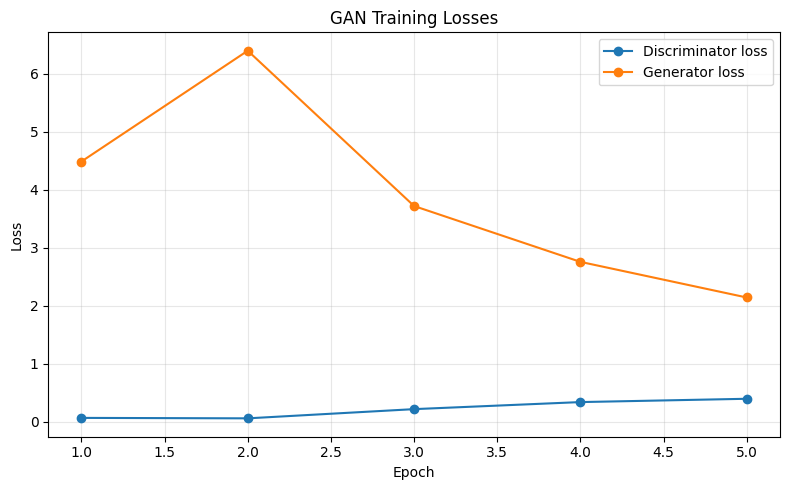

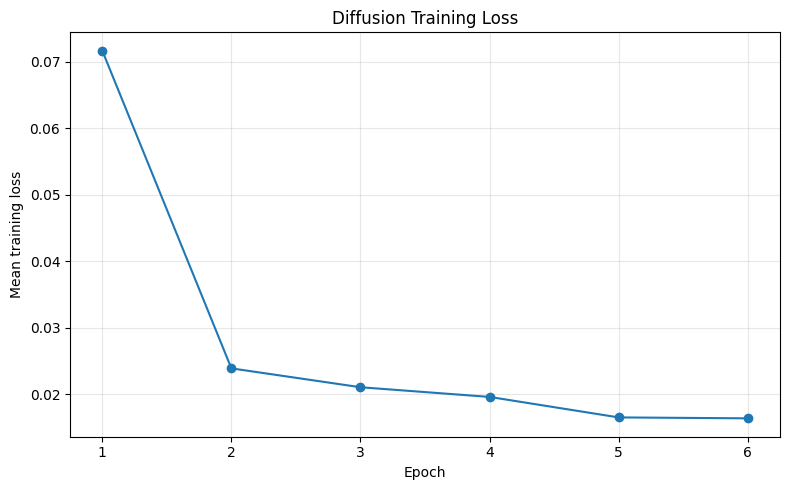

NOTEBOOK 11 COMPARISON COMPLETE

Training comparison:
           model  epochs  batches_per_epoch  total_training_seconds  final_generator_loss  final_discriminator_loss  individual_synthetic_images_available                qualitative_preview_observation  final_diffusion_training_loss
             GAN       5                132                   70.36              2.144427                  0.399675                                  False    Grid-like repetitive patterns and artifacts                            NaN
Diffusion (DDPM)       6                265                  213.05                   NaN                       NaN                                  False Cloudy/noisy patterns; not recognizably ocular                       0.016369

Outputs saved to: /kaggle/working/ubiris_v2_project/notebook11_gan_vs_diffusion
Diffusion_training_history.csv: 328 bytes
Diffusion_training_loss.png: 45,634 bytes
GAN_training_history.csv: 365 bytes
GAN_training_losses.png: 50,202 bytes
GAN_vs_D

In [9]:

from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path("/kaggle/working/ubiris_v2_project")
GAN_DIR = PROJECT / "notebook07_gan_augmentation"
DIFF_DIR = PROJECT / "notebook06_diffusion_training"
QUALITY_DIR = PROJECT / "notebook08_quality_diversity"
OUT_DIR = PROJECT / "notebook11_gan_vs_diffusion"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Load saved histories and quality summary
gan = pd.read_csv(GAN_DIR / "UBIRIS_V2_GAN_training_history.csv")
diff = pd.read_csv(DIFF_DIR / "UBIRIS_V2_ddpm_training_history.csv")
quality = pd.read_csv(
    QUALITY_DIR / "UBIRIS_V2_quality_diversity_summary.csv"
)

# 2. Save training histories side by side (loss scales differ)
gan_out = gan.rename(columns={
    "discriminator_loss": "gan_discriminator_loss",
    "generator_loss": "gan_generator_loss",
    "epoch_seconds": "gan_epoch_seconds"
})
diff_out = diff.rename(columns={
    "mean_training_loss": "diffusion_training_loss",
    "epoch_seconds": "diffusion_epoch_seconds"
})

gan_out.to_csv(OUT_DIR / "GAN_training_history.csv", index=False)
diff_out.to_csv(OUT_DIR / "Diffusion_training_history.csv", index=False)
quality.to_csv(OUT_DIR / "Quality_diversity_summary.csv", index=False)

# 3. Plot GAN losses
plt.figure(figsize=(8, 5))
plt.plot(gan["epoch"], gan["discriminator_loss"], marker="o",
         label="Discriminator loss")
plt.plot(gan["epoch"], gan["generator_loss"], marker="o",
         label="Generator loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Losses")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "GAN_training_losses.png", dpi=160)
plt.show()
plt.close()

# 4. Plot diffusion loss
plt.figure(figsize=(8, 5))
plt.plot(diff["epoch"], diff["mean_training_loss"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Mean training loss")
plt.title("Diffusion Training Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "Diffusion_training_loss.png", dpi=160)
plt.show()
plt.close()

# 5. Create a comparison table (no invalid cross-model loss comparison)
comparison = pd.DataFrame([
    {
        "model": "GAN",
        "epochs": len(gan),
        "batches_per_epoch": int(gan["batches"].iloc[0]),
        "total_training_seconds": round(gan["epoch_seconds"].sum(), 2),
        "final_generator_loss": float(gan["generator_loss"].iloc[-1]),
        "final_discriminator_loss": float(gan["discriminator_loss"].iloc[-1]),
        "individual_synthetic_images_available": False,
        "qualitative_preview_observation":
            "Grid-like repetitive patterns and artifacts"
    },
    {
        "model": "Diffusion (DDPM)",
        "epochs": len(diff),
        "batches_per_epoch": int(diff["batches"].iloc[0]),
        "total_training_seconds": round(diff["epoch_seconds"].sum(), 2),
        "final_generator_loss": None,
        "final_discriminator_loss": None,
        "final_diffusion_training_loss":
            float(diff["mean_training_loss"].iloc[-1]),
        "individual_synthetic_images_available": False,
        "qualitative_preview_observation":
            "Cloudy/noisy patterns; not recognizably ocular"
    }
])
comparison.to_csv(OUT_DIR / "GAN_vs_Diffusion_comparison.csv", index=False)

# 6. Research summary
summary = {
    "dataset": "UBIRIS V2",
    "gan_epochs": int(len(gan)),
    "diffusion_epochs": int(len(diff)),
    "gan_total_training_seconds": round(float(gan["epoch_seconds"].sum()), 2),
    "diffusion_total_training_seconds": round(float(diff["epoch_seconds"].sum()), 2),
    "gan_final_generator_loss": float(gan["generator_loss"].iloc[-1]),
    "gan_final_discriminator_loss": float(gan["discriminator_loss"].iloc[-1]),
    "diffusion_final_training_loss": float(diff["mean_training_loss"].iloc[-1]),
    "individual_generated_samples_available": False,
    "conclusion": (
        "Both generative models were trained, but the saved previews did not "
        "show convincing ocular images. GAN previews contained repetitive "
        "artifacts; diffusion previews remained cloudy/noisy. The training "
        "losses are not directly comparable across model types. Quality "
        "metrics for composite preview grids cannot establish individual-image "
        "quality, identity preservation, privacy, or recognition improvement."
    ),
    "limitations": [
        "GAN and diffusion individual generated images were unavailable for evaluation.",
        "Preview-grid statistics describe composite grids, not individual images.",
        "No identity-preservation or membership-inference result is established here.",
        "Loss values use different objectives and should not be ranked against each other."
    ]
}
with open(OUT_DIR / "GAN_vs_Diffusion_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

conclusion = """## Conclusion

The GAN and DDPM diffusion models were trained on the UBIRIS V2 training data.
The GAN was trained for five epochs and the diffusion model for six epochs.
Their training objectives and loss scales differ, so their loss values are not
directly comparable.

The saved GAN previews showed repetitive grid-like artifacts, while the
diffusion previews remained cloudy/noisy and were not recognizably ocular.
Although the diffusion training loss decreased over its six epochs, this alone
does not demonstrate realistic image generation.

Quantitative image descriptors were available for real and traditionally
augmented samples, but the GAN and diffusion measurements were calculated on
composite preview grids rather than individual generated images. They therefore
cannot support a fair per-image quality or diversity ranking.

This experiment does not establish identity preservation, privacy protection,
or improved recognition from GAN or diffusion samples. Further evaluation
would require saved individual generated images and controlled, validated
metrics. These limitations are recorded as research findings rather than
claiming successful synthetic ocular generation.
"""
(OUT_DIR / "Notebook11_Conclusion.md").write_text(conclusion)

print("NOTEBOOK 11 COMPARISON COMPLETE")
print("\nTraining comparison:")
print(comparison.to_string(index=False))
print("\nOutputs saved to:", OUT_DIR)
for p in sorted(OUT_DIR.iterdir()):
    if p.is_file():
        print(f"{p.name}: {p.stat().st_size:,} bytes")


In [10]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display
import json
import pandas as pd

PROJECT = Path("/kaggle/working/ubiris_v2_project")
OUT_DIR = PROJECT / "notebook11_gan_vs_diffusion"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 1. Final research conclusion
# --------------------------------------------------
conclusion = """# Notebook 11 — GAN vs. Diffusion Comparison

## Objective
This experiment compared the training behavior and saved preview observations
of a GAN and a denoising diffusion probabilistic model (DDPM) trained using
UBIRIS V2 data.

## Training Results
- **GAN:** trained for 5 epochs, with 132 batches per epoch. The final generator
  loss was 2.144427 and the final discriminator loss was 0.399675.
- **Diffusion (DDPM):** trained for 6 epochs, with 265 batches per epoch.
  The mean training loss decreased from 0.071654 in epoch 1 to 0.016369
  in epoch 6.

The loss values are not directly comparable because GAN and diffusion models
optimize different objectives.

## Qualitative Observations
- GAN preview grids contained repetitive, grid-like patterns and artifacts.
- Diffusion preview images remained cloudy/noisy and were not recognizably ocular.

## Quality and Diversity Evaluation
The available exploratory image descriptors were calculated on real images,
traditionally augmented images, and composite GAN/diffusion preview grids.
The generated-model measurements therefore describe preview grids rather than
individual synthetic images. They cannot establish a reliable per-image
quality or diversity ranking.

## Limitations
1. Individual GAN- and diffusion-generated images were not available for
   quantitative evaluation in this comparison.
2. These experiments do not establish identity preservation, privacy protection,
   or improved recognition accuracy from GAN or diffusion augmentation.
3. Training losses alone do not establish perceptual image quality.
4. The experiments were limited in training duration and should be considered
   preliminary.

## Conclusion
Both generative approaches were trained, but neither produced convincing
ocular samples in the saved previews. The diffusion model showed a decreasing
training loss, while the GAN showed changing generator and discriminator
losses. These observations are useful diagnostic findings, not proof that one
approach is superior. Future evaluation requires individual generated images,
validated image-quality and diversity measures, identity-preservation testing,
and controlled recognition experiments.

The findings are reported as observed, without claiming successful synthetic
ocular generation or demonstrated privacy benefits.
"""

conclusion_path = OUT_DIR / "Notebook11_Conclusion.md"
conclusion_path.write_text(conclusion, encoding="utf-8")

print("FINAL CONCLUSION")
print("=" * 60)
print(conclusion)

# --------------------------------------------------
# 2. Verify expected comparison outputs
# --------------------------------------------------
required = [
    "GAN_training_history.csv",
    "Diffusion_training_history.csv",
    "Quality_diversity_summary.csv",
    "GAN_vs_Diffusion_comparison.csv",
    "GAN_vs_Diffusion_summary.json",
    "GAN_training_losses.png",
    "Diffusion_training_loss.png",
    "Notebook11_Conclusion.md",
]

print("\nOUTPUT VERIFICATION")
missing = []
for name in required:
    p = OUT_DIR / name
    ok = p.is_file() and p.stat().st_size > 0
    print(f"{'OK' if ok else 'MISSING':8} {name}")
    if not ok:
        missing.append(name)

if missing:
    raise FileNotFoundError("Missing outputs: " + ", ".join(missing))

# --------------------------------------------------
# 3. Create ZIP containing all Notebook 11 results
# --------------------------------------------------
zip_path = PROJECT / "UBIRIS_V2_Notebook11_Results.zip"

with ZipFile(zip_path, "w", ZIP_DEFLATED) as zf:
    for p in sorted(OUT_DIR.rglob("*")):
        if p.is_file():
            zf.write(p, arcname=p.relative_to(PROJECT))

# --------------------------------------------------
# 4. Verify ZIP integrity and list its contents
# --------------------------------------------------
with ZipFile(zip_path, "r") as zf:
    bad_file = zf.testzip()
    if bad_file:
        raise RuntimeError(f"ZIP integrity check failed: {bad_file}")
    archived_files = zf.namelist()

print("\nZIP VERIFICATION")
print("Archive:", zip_path)
print("Files archived:", len(archived_files))
print(f"ZIP size: {zip_path.stat().st_size / (1024 * 1024):.2f} MB")
print("Integrity check: PASSED")

for name in archived_files:
    print(" -", name)

print("\nDOWNLOAD NOTEBOOK 11 RESULTS:")
display(FileLink(str(zip_path)))


FINAL CONCLUSION
# Notebook 11 — GAN vs. Diffusion Comparison

## Objective
This experiment compared the training behavior and saved preview observations
of a GAN and a denoising diffusion probabilistic model (DDPM) trained using
UBIRIS V2 data.

## Training Results
- **GAN:** trained for 5 epochs, with 132 batches per epoch. The final generator
  loss was 2.144427 and the final discriminator loss was 0.399675.
- **Diffusion (DDPM):** trained for 6 epochs, with 265 batches per epoch.
  The mean training loss decreased from 0.071654 in epoch 1 to 0.016369
  in epoch 6.

The loss values are not directly comparable because GAN and diffusion models
optimize different objectives.

## Qualitative Observations
- GAN preview grids contained repetitive, grid-like patterns and artifacts.
- Diffusion preview images remained cloudy/noisy and were not recognizably ocular.

## Quality and Diversity Evaluation
The available exploratory image descriptors were calculated on real images,
traditionally a

/kaggle/working/ubiris_v2_project/UBIRIS_V2_Notebook11_Results.zip